In [1]:
import ast
import collections
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from matplotlib.patches import Patch
import rdkit.Chem as Chem
from scipy.stats import linregress
from rdkit.Chem import Descriptors

# Protein family distribution of enantiomer pairs

In [2]:
def plot_distribution(series: pd.Series, xlabel: str, ylabel: str, top_n: int = 20, figsize=(20,10), rotation=45, bar_color="cornflowerblue"):
    value_counts = series.value_counts()
    total_count = value_counts.sum()
    # Print out the top_n protein family names and their percentage
    print(f"Top {top_n} protein family names:")
    for i, family in enumerate(value_counts.index[:top_n], 1):
        count = value_counts[family]
        percent = (count / total_count) * 100
        print(f"{i}. {family} - {percent:.2f}%")

    top_n_percent = (value_counts.values[:top_n].sum() / total_count) * 100
    print(f"Top {top_n} protein families represent {top_n_percent:.2f}% of all data.")

    plt.figure(figsize=figsize)
    ax = sns.barplot(
        x=value_counts.index[:top_n],
        y=value_counts.values[:top_n],
        color=bar_color,
        edgecolor='black'
    )
    plt.xlabel(xlabel, fontsize=15)
    plt.ylabel(ylabel, fontsize=15)
    plt.xticks(rotation=rotation, ha='right', fontsize=12)
    plt.yticks(fontsize=13)
    for idx, value in enumerate(value_counts.values[:top_n]):
        plt.text(idx, value + max(value_counts.values[:top_n])*0.01, str(value), ha='center', va='bottom', fontsize=10)
    plt.tight_layout()
    plt.savefig(f'protein_family_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()

def stringify_entries(cell):
    if isinstance(cell, list):
        return ", ".join(str(x) for x in cell)
    else:
        return cell

load annotated protein family information

In [3]:
df_fam_sim_annotated = pd.read_csv('../Data/Notebook_reproduce_data/Annotated_protein_family_info.csv')
display(df_fam_sim_annotated.head(3))
df_fam_sim_annotated['protein_family_sim_str'] = df_fam_sim_annotated['protein_family_sim_str'].str.replace('family', '', case=False)
print(df_fam_sim_annotated['protein_family_sim_str'].value_counts())

,inchi_core,uniprot_id,protein_family_sim_str,identifier,pdb_id,note
0,InChI=1S/C18H14N4O3/c1-18(16(24)21-17(25)22-18...,Q9H2K2,ARTD/PARP family,5owt_F37_A_1203,5owt,NaN
1,InChI=1S/C14H18BrN3O/c15-10-5-12(11-8-17-18-13...,P14902,"indoleamine 2,3-dioxygenase family",7e0s_HU6_A_502,7e0s,NaN
2,InChI=1S/C21H30FN5/c1-15-9-19(27-21(23)10-15)1...,P29473,NOS family,3jwz_J14_A_800,3jwz,NaN


protein_family_sim_str
nuclear hormone receptor               9
dihydrofolate reductase                6
Tyr protein kinase                     6
NOS                                    5
CMGC Ser/Thr protein kinase            5
                                      ..
glycosyltransferase 41                 1
tubulin                                1
purine-cytosine permease (2.A.39)      1
HDGF                                   1
glycosyl hydrolase 7 (cellulase C)     1
Name: count, Length: 162, dtype: int64


Top 14 protein family names:
1. nuclear hormone receptor  - 3.81%
2. dihydrofolate reductase  - 2.54%
3. Tyr protein kinase  - 2.54%
4. NOS  - 2.12%
5. CMGC Ser/Thr protein kinase  - 2.12%
6. ARTD/PARP  - 1.69%
7. cytochrome P450  - 1.69%
8. Class-B beta-lactamase  - 1.69%
9. MIP/aquaporin (TC 1.A.8)  - 1.27%
10. aldo/keto reductase  - 1.27%
11. type-B carboxylesterase/lipase  - 1.27%
12. AGC Ser/Thr protein kinase  - 1.27%
13. peptidase M10A  - 1.27%
14. cyclic nucleotide phosphodiesterase  - 1.27%
Top 14 protein families represent 25.85% of all data.


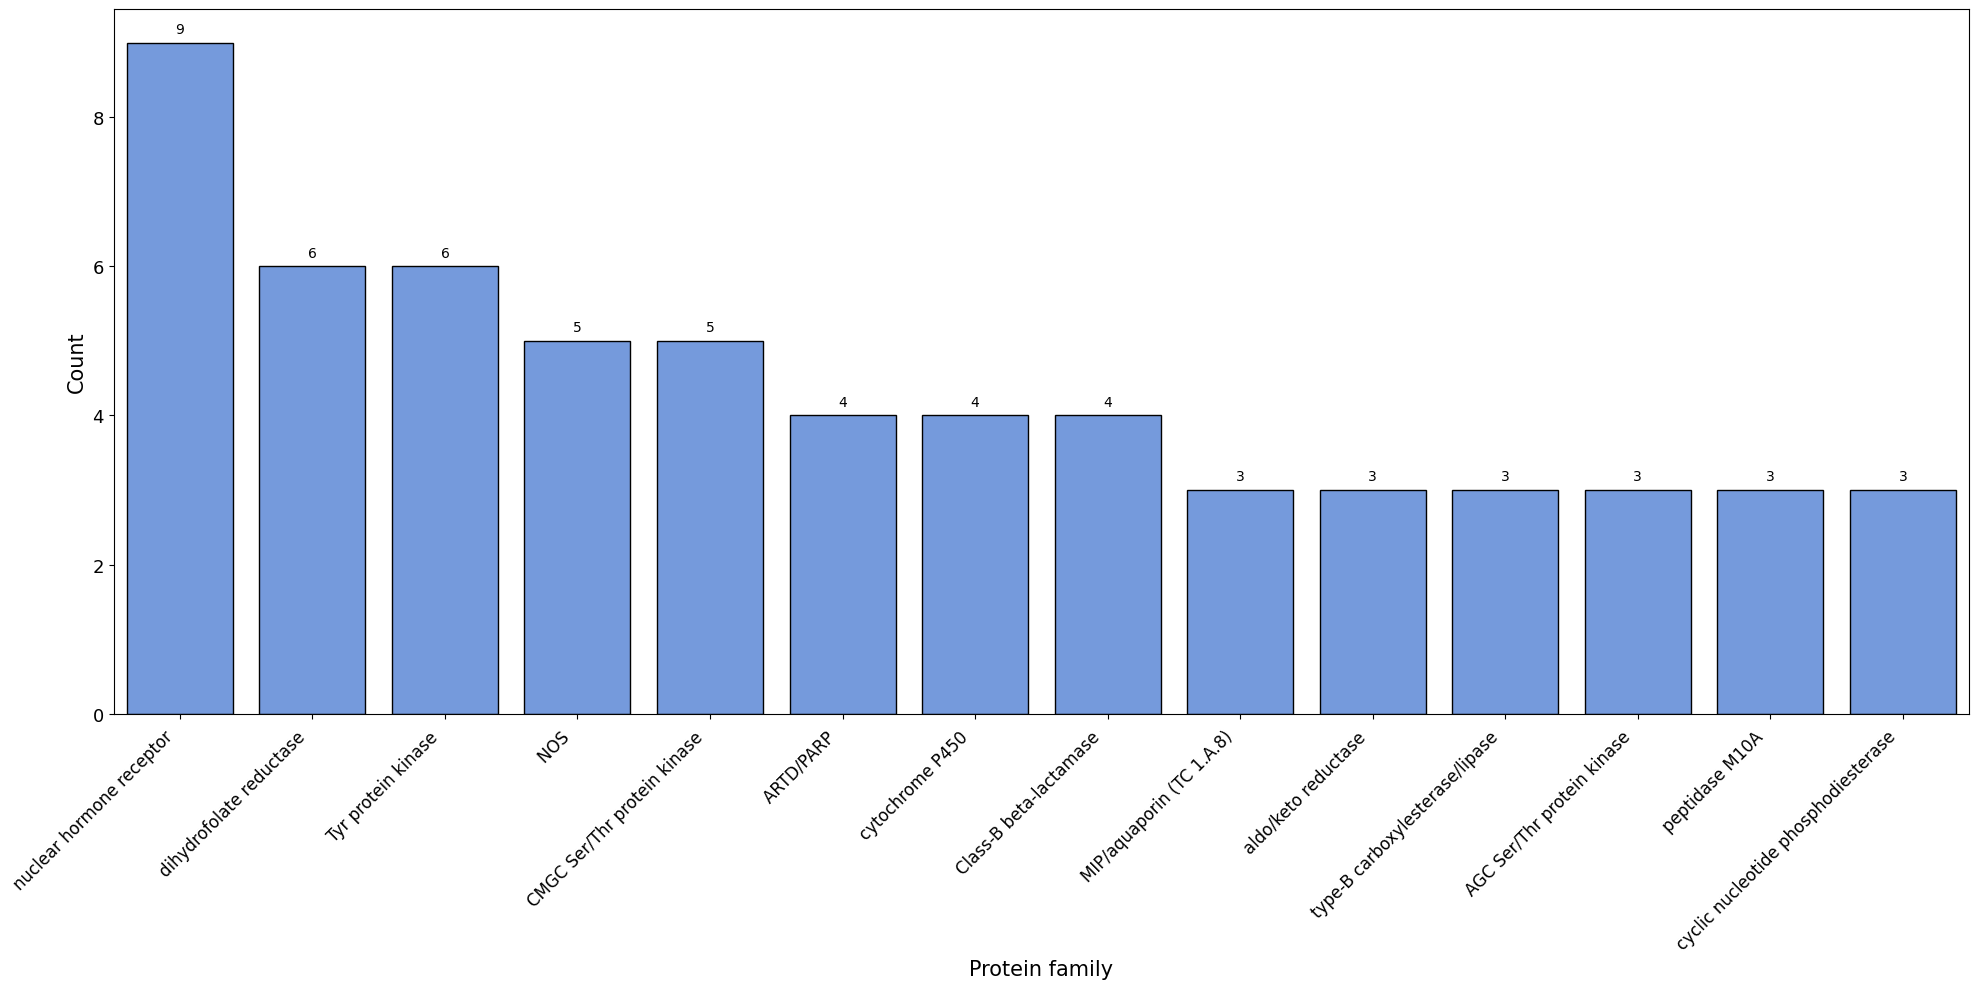

In [4]:
plot_distribution(
    df_fam_sim_annotated['protein_family_sim_str'].apply(stringify_entries),
    xlabel="Protein family",
    ylabel="Count",
    top_n=14
)

Distribution of the protein family in four curated categories

In [5]:
manual_check_folder = '../Data/Notebook_reproduce_data/Manual_curation'
all_records = []
uniprot_to_family = df_fam_sim_annotated.set_index('uniprot_id')['protein_family_sim_str'].to_dict()

for file in os.listdir(manual_check_folder):
    if file.endswith('.csv') and not 'manualcheck_invalid' in file:
        file_path = os.path.join(manual_check_folder, file)
        df = pd.read_csv(file_path, delimiter='\t')
        df_non4letter_title = df[df['Title'].astype(str).str.len() != 4]
        grouped = df_non4letter_title.groupby('group')
        for group_name, group_df in grouped:
            for idx, row in group_df.iterrows():
                label = row.get('category_manual_check', None)
                ids = row['ID']
                if pd.notna(ids):
                    if isinstance(ids, str) and ids.startswith('[') and ids.endswith(']'):
                        try:
                            ids_list = ast.literal_eval(ids)
                        except Exception:
                            ids_list = []
                    else:
                        ids_list = [ids]
                    for idstr in ids_list:
                        uniprot_id = idstr.split('_')[0]
                        protein_family = uniprot_to_family.get(uniprot_id, None)
                        if protein_family is not None:
                            all_records.append({
                                "group": group_name,
                                "uniprot_id": uniprot_id,
                                "protein_family": protein_family,
                                "manual_label": label
                            })
plot_df = pd.DataFrame(all_records)
plot_df['manual_label'] = plot_df['manual_label'].astype(str)
plot_df['group'] = plot_df['group'].astype(str)
display(plot_df.head(3))

,group,uniprot_id,protein_family,manual_label
0,{'g000293_4931b3e06d'},F2QVG4,MIP/aquaporin (TC 1.A.8),2
1,{'g000293_4931b3e06d'},F2QVG4,MIP/aquaporin (TC 1.A.8),2
2,{'g000293_4931b3e06d'},F2QVG4,MIP/aquaporin (TC 1.A.8),2


Accumulated (row): Entries in Cat 1.1 with protein_family containing 'kinase': 98/650 (15.08%)
Accumulated (row): Entries in Cat 1.2 with protein_family containing 'lipase': 15/400 (3.75%)
Accumulated (row): Entries in Cat 1.2 with protein_family containing 'cytochrome p450': 12/400 (3.00%)


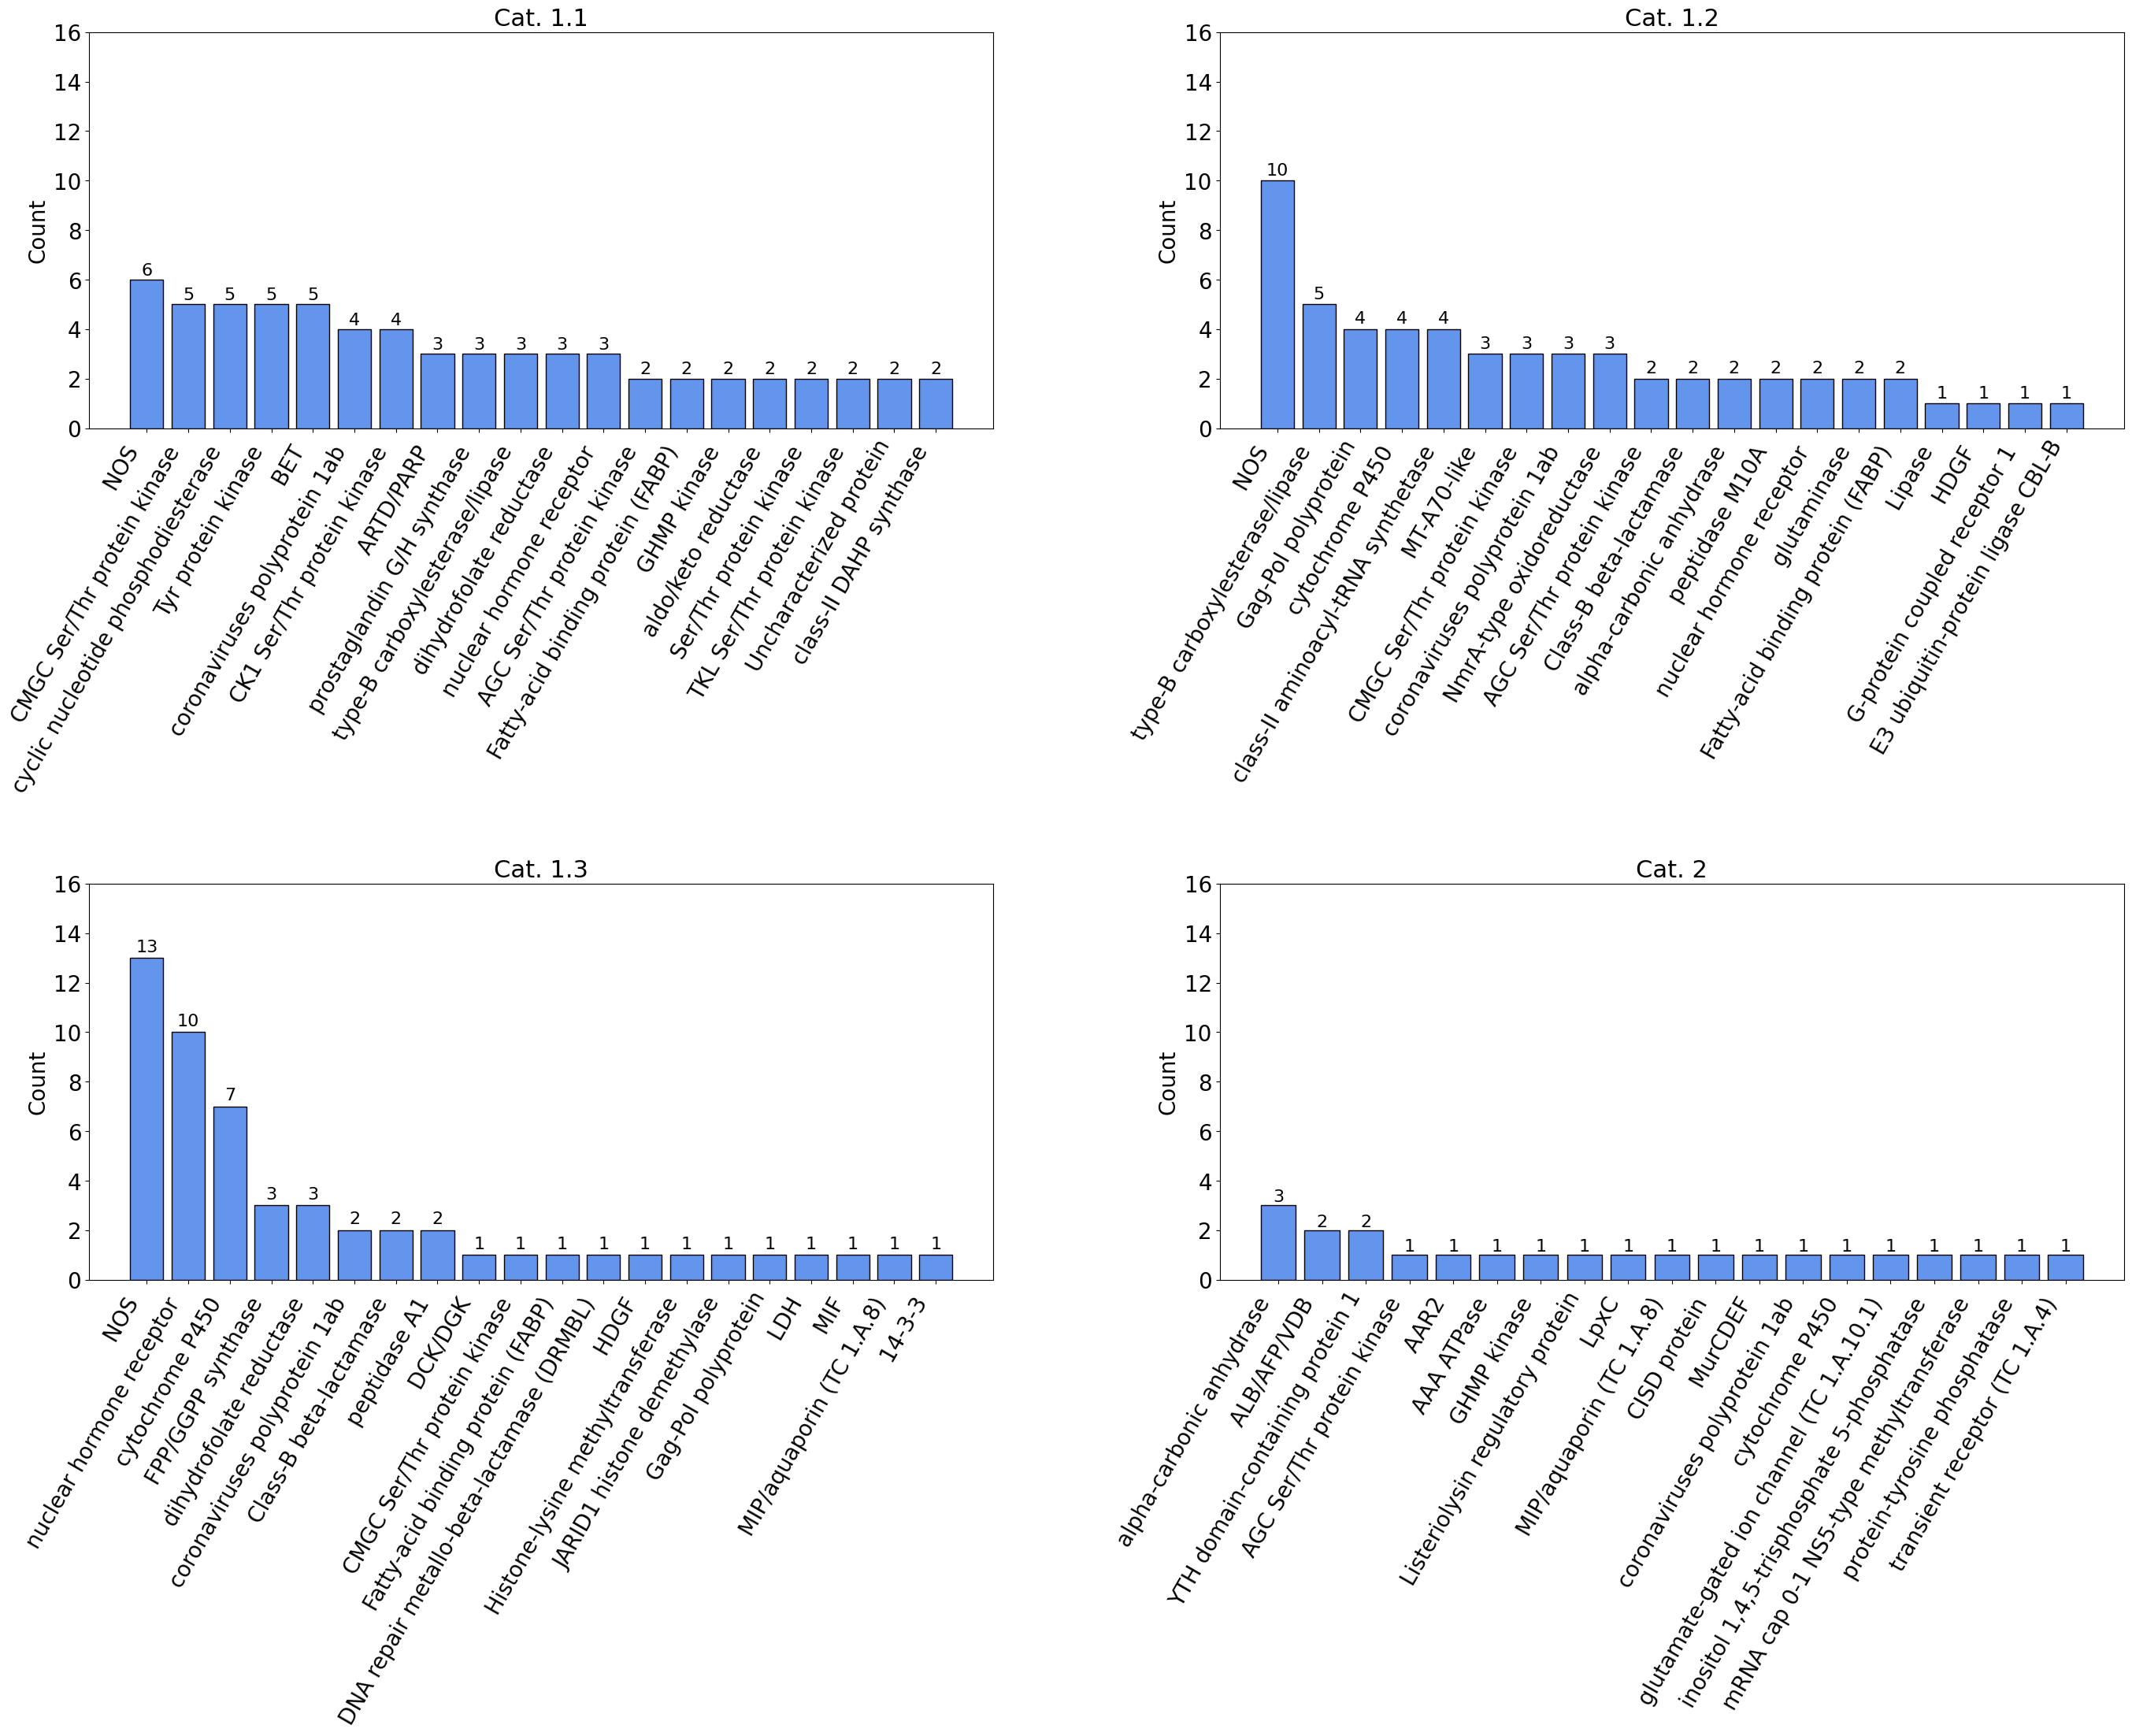

In [6]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

category_label_map = {
    "1.1": "Cat. 1.1",
    "1.2": "Cat. 1.2",
    "1.3": "Cat. 1.3",
    "2": "Cat. 2",
}

codes_in_data = [x for x in plot_df["manual_label"].dropna().unique()]
codes_in_data_sorted = [code for code in ["1.1", "1.2", "1.3", "2"] if code in codes_in_data]
pretty_labels_sorted = [category_label_map.get(code, code) for code in codes_in_data_sorted]

# Adjusted parameters
fig_width = 34
fig_height = 22
title_fontsize = 22
label_fontsize = 20
tick_fontsize = 20
bar_text_fontsize = 16
top_n = 20  # Number to plot per category

# ── Build a global, stable color map for all protein families ──────────────
all_families = sorted(plot_df["protein_family"].dropna().unique().tolist())
n_families = len(all_families)
cmap = plt.get_cmap("tab20", n_families)
family_to_color = {fam: mcolors.rgb2hex(cmap(i)) for i, fam in enumerate(all_families)}

# Calculate accumulated counts for "kinase" families vs. all families in category 1.1
df_cat_1_1 = plot_df[plot_df["manual_label"] == "1.1"].copy()
df_cat_1_1 = df_cat_1_1[df_cat_1_1["protein_family"].notna()]
is_kinase = df_cat_1_1["protein_family"].str.lower().str.contains("kinase")
kinase_total_count = is_kinase.sum()
all_total_count = len(df_cat_1_1)
print(f"Accumulated (row): Entries in Cat 1.1 with protein_family containing 'kinase': "
    f"{kinase_total_count}/{all_total_count} "
    f"({(kinase_total_count/all_total_count*100) if all_total_count > 0 else 0:.2f}%)")

# Calculate accumulated counts for "lipase" and "cytochrome p450" in category 1.2
df_cat_1_2 = plot_df[plot_df["manual_label"] == "1.2"].copy()
df_cat_1_2 = df_cat_1_2[df_cat_1_2["protein_family"].notna()]
is_lipase = df_cat_1_2["protein_family"].str.lower().str.contains("lipase")
is_cytochrome_p450 = df_cat_1_2["protein_family"].str.lower().str.contains("cytochrome p450")
lipase_total_count = is_lipase.sum()
cytochrome_p450_total_count = is_cytochrome_p450.sum()
all_total_count_1_2 = len(df_cat_1_2)
print(f"Accumulated (row): Entries in Cat 1.2 with protein_family containing 'lipase': "
    f"{lipase_total_count}/{all_total_count_1_2} "
    f"({(lipase_total_count/all_total_count_1_2*100) if all_total_count_1_2 > 0 else 0:.2f}%)")
print(f"Accumulated (row): Entries in Cat 1.2 with protein_family containing 'cytochrome p450': "
    f"{cytochrome_p450_total_count}/{all_total_count_1_2} "
    f"({(cytochrome_p450_total_count/all_total_count_1_2*100) if all_total_count_1_2 > 0 else 0:.2f}%)")

if len(codes_in_data_sorted) == 0:
    print("No data to plot for protein family vs. manual label (no categories found).")
else:
    n_rows, n_cols = 2, 2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height))
    axes = axes.flatten()

    for ax, code in zip(axes, codes_in_data_sorted):
        df_cat = plot_df[plot_df["manual_label"] == code]
        group_counts = (
            df_cat.groupby("protein_family")["group"]
            .nunique()
            .sort_values(ascending=False)
            .head(top_n)
        )
        x_vals = group_counts.index.tolist()
        y_vals = group_counts.values
        colors = [family_to_color.get(fam, "#BBBBBB") for fam in x_vals]
        ax.bar(x_vals, y_vals, color='cornflowerblue', edgecolor="black")
        ax.set_title(category_label_map.get(code, code), fontsize=title_fontsize)
        ax.set_ylabel("Count", fontsize=label_fontsize)
        ax.set_xticks(range(len(x_vals)))
        ax.set_xticklabels(x_vals, rotation=60, fontsize=tick_fontsize, ha="right") 
        ax.set_ylim(0, 16)
        ax.tick_params(axis="y", labelsize=tick_fontsize)

        for idx2, value in enumerate(y_vals):
            ax.text(
                idx2,
                value + (max(y_vals) * 0.01 if value > 0 else 0.01),
                str(value),
                ha="center",
                va="bottom",
                fontsize=bar_text_fontsize,
            )
    fig.subplots_adjust(hspace=1.15, wspace=0.25, top=0.94, bottom=0.22, left=0.04, right=0.80)
    fig.savefig("protein_family_distribution_full_figure.png", dpi=300, bbox_inches="tight")
    plt.show()

# Distribution of three complementary features in the dataset

In [7]:
feature_table = pd.read_csv("../Data/Notebook_reproduce_data/feature_table.csv")
print(feature_table.columns)
display(feature_table.head(3))

Index(['PSG_identifier', 'n_structures', 'n_m0_structures', 'n_m1_structures',
       'atom_count_unique_values', 'atom_count_by_file',
       'maximum_relatedness_m0_file', 'maximum_relatedness_m1_file',
       'maximum_relatedness_rmsd_A', 'maximum_relatedness_silirid_similarity',
       'maximum_relatedness_m0_silirid', 'maximum_relatedness_m1_silirid'],
      dtype='object')


,PSG_identifier,n_structures,n_m0_structures,n_m1_structures,atom_count_unique_values,atom_count_by_file,maximum_relatedness_m0_file,maximum_relatedness_m1_file,maximum_relatedness_rmsd_A,maximum_relatedness_silirid_similarity,maximum_relatedness_m0_silirid,maximum_relatedness_m1_silirid
0,g000001_b55a025257,6,4,2,"21,23,25,31,32",interaction_7pql_80S_A_301_m0.tsv=23; interact...,NaN,NaN,NaN,NaN,NaN,NaN
1,g000013_cb46fef414,7,5,2,20,interaction_5tiw_OAQ_A_302_m0.tsv=20; interact...,interaction_6b52_OAQ_A_302_m0.tsv,interaction_5tix_OQR_B_302_m1.tsv,3.218487,0.757576,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,..."
2,g000045_359154acb2,13,12,1,27,interaction_5bk7_EQJ_A_400_m0.tsv=27; interact...,interaction_6c92_EQJ_A_401_m0.tsv,interaction_5dj3_5DK_C_500_m1.tsv,2.537710,0.470588,"0,0,0,0,0,0,0,0,0,0,3,0,0,2,0,0,0,0,0,0,0,3,0,...","0,0,0,0,0,0,0,0,0,0,3,0,0,2,0,0,0,0,0,0,0,2,0,..."


In [8]:
def extract_group_key(psg_identifier):
    parts = str(psg_identifier).split('_')
    if len(parts) >= 3 and parts[1] == 'inchi':
        return f"{{'{parts[0]}_{parts[2]}'}}"
    if len(parts) >= 2:
        return f"{{'{parts[0]}_{parts[1]}'}}"
    return None

# Create a mapping from plot_df group to manual_label (as string key)
group_to_manual = plot_df.set_index('group')['manual_label'].to_dict()

feature_table['manual_label'] = feature_table['PSG_identifier'].apply(
    lambda x: group_to_manual.get(extract_group_key(x), None)
)

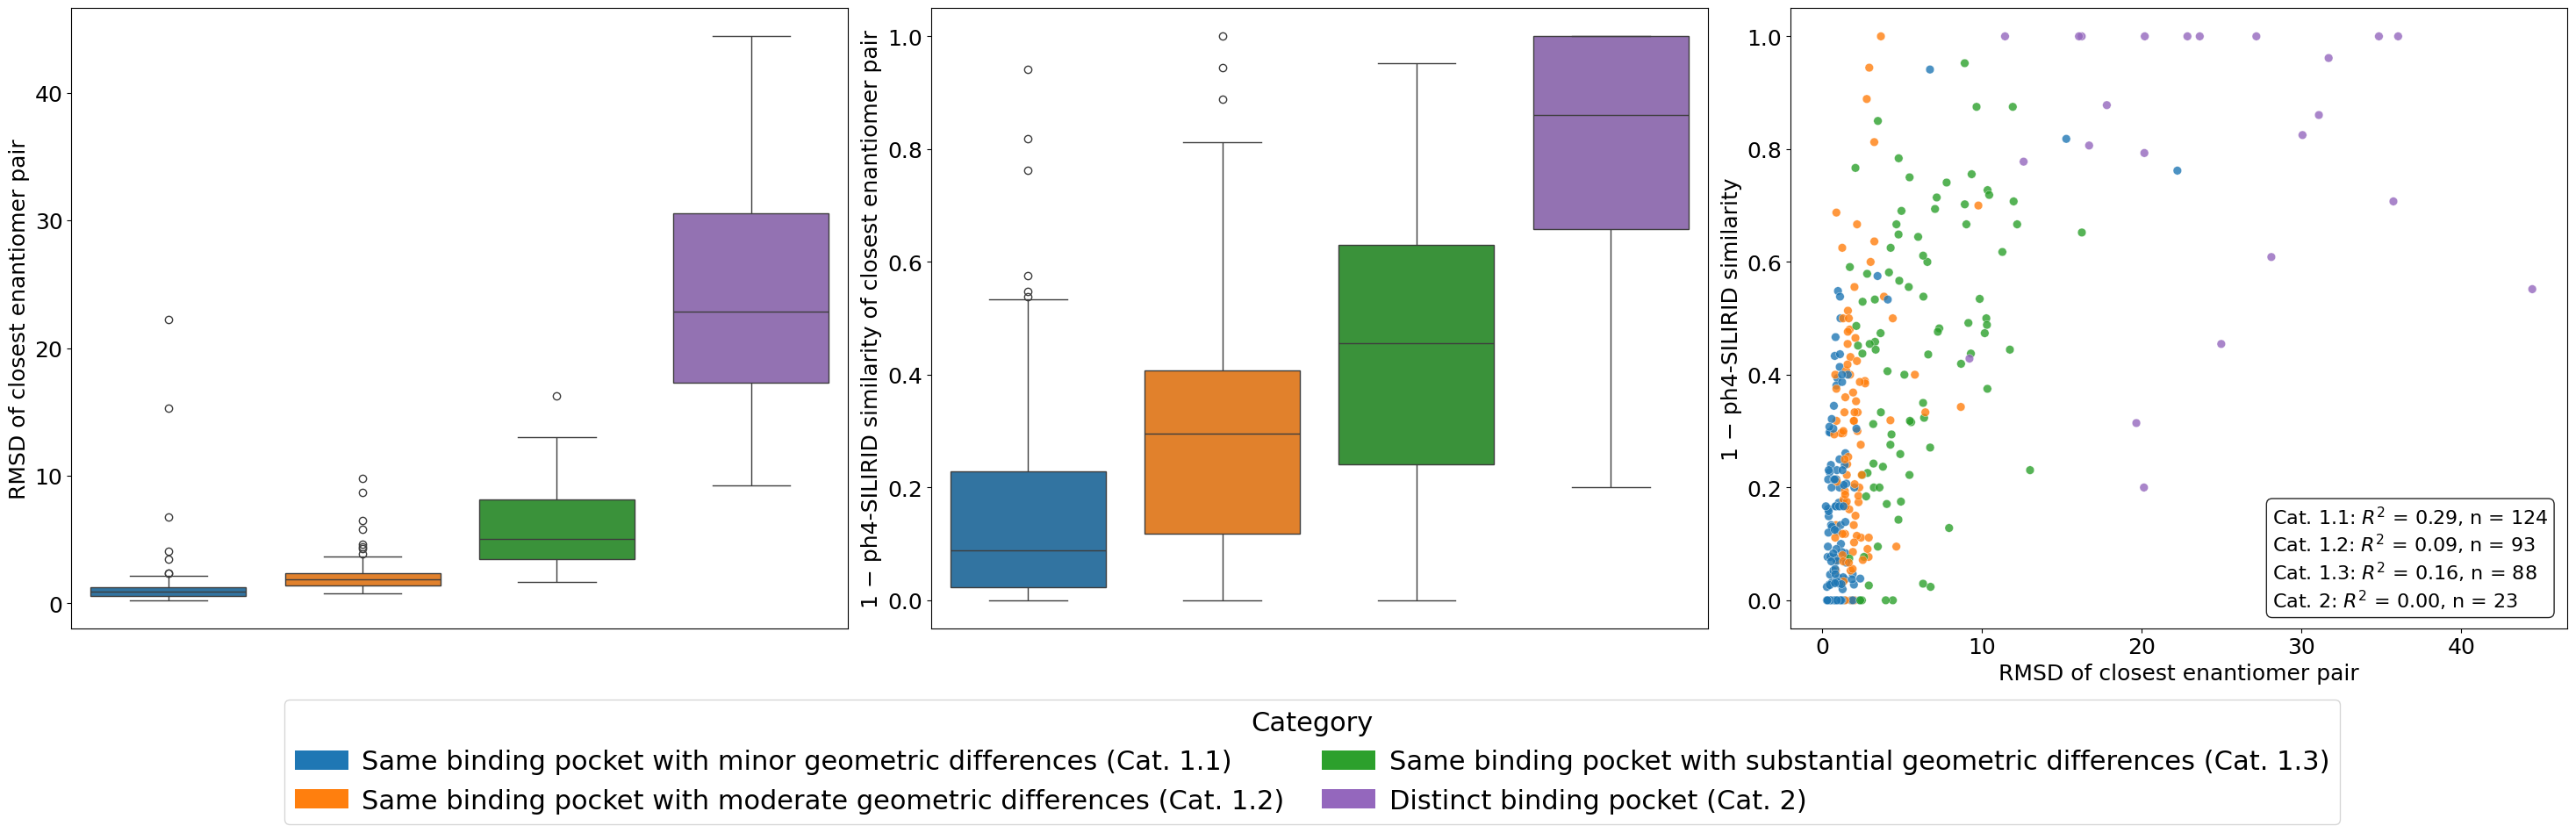

In [9]:
feature_table["manual_label"] = (
    feature_table["manual_label"].astype(str)
)
feature_table["maximum_relatedness_silirid_distance"] = (
    1 - feature_table["maximum_relatedness_silirid_similarity"]
)
# Only allow the first four valid categories, ignore 'invalid' and other stray labels
valid_labels = ["1.1", "1.2", "1.3", "2"]
feature_table_plot = feature_table[feature_table["manual_label"].isin(valid_labels)]
labels_sorted = valid_labels  # keep intended logical order
category_label_map = {
    "1.1": "Same binding pocket with minor geometric differences (Cat. 1.1)",
    "1.2": "Same binding pocket with moderate geometric differences (Cat. 1.2)",
    "1.3": "Same binding pocket with substantial geometric differences (Cat. 1.3)",
    "2": "Distinct binding pocket (Cat. 2)",
}

palette_colors = sns.color_palette("tab10", n_colors=len(labels_sorted))
# Change the last color to a purple-ish color instead of red
if len(palette_colors) > 0:
    palette_colors = list(palette_colors)
    palette_colors[-1] = (148/255, 103/255, 189/255)  # matplotlib tab10 purple

label_to_color = dict(zip(labels_sorted, palette_colors))

boxplot_columns = [
    (
        "maximum_relatedness_rmsd_A",
        "RMSD of closest enantiomer pair"
    ),
    (
        "maximum_relatedness_silirid_distance",
        "1 − ph4-SILIRID similarity of closest enantiomer pair"
    ),
]
label_fontsize = 18
tick_fontsize = 18
legend_fontsize = 22
title_fontsize = 18
fig, axes = plt.subplots(
    1,
    3,
    figsize=(30, 8)
)
legend_handles = None
for ax, (y, ylabel) in zip(
    axes[:2],
    boxplot_columns
):
    sns.boxplot(
        data=feature_table_plot,
        x="manual_label",
        y=y,
        hue="manual_label",
        order=labels_sorted,
        hue_order=labels_sorted,
        palette=label_to_color,
        dodge=False,
        showfliers=True,
        ax=ax,
        legend=False,
    )
    ax.set_xlabel(
        "",
        fontsize=label_fontsize
    )
    ax.set_xticks([])
    ax.set_xticklabels([])
    ax.set_ylabel(
        ylabel,
        fontsize=label_fontsize
    )
    ax.tick_params(
        axis="y",
        labelsize=tick_fontsize
    )
    if ax is axes[0]:
        legend_handles = [
            Patch(
                facecolor=label_to_color[code],
                label=category_label_map.get(
                    str(code),
                    str(code)
                )
            )
            for code in labels_sorted
        ]
plot_df = feature_table_plot[
    [
        "maximum_relatedness_rmsd_A",
        "maximum_relatedness_silirid_distance",
        "manual_label"
    ]
].copy()
pretty_names = {
    "maximum_relatedness_rmsd_A":
        "RMSD of closest enantiomer pair",

    "maximum_relatedness_silirid_distance":
        "1 − ph4-SILIRID similarity",

    "manual_label":
        "Manual Label"
}
plot_df = plot_df.rename(
    columns=pretty_names
)
regression_results = {}
for label in labels_sorted:
    class_df = plot_df[
        plot_df["Manual Label"] == str(label)
    ].dropna(
        subset=[
            "RMSD of closest enantiomer pair",
            "1 − ph4-SILIRID similarity"
        ]
    )
    x = class_df[
        "RMSD of closest enantiomer pair"
    ]
    y = class_df[
        "1 − ph4-SILIRID similarity"
    ]
    result = linregress(
        x,
        y
    )
    regression_results[str(label)] = {
        "r": result.rvalue,
        "r2": result.rvalue ** 2,
        "slope": result.slope,
        "intercept": result.intercept,
        "p_value": result.pvalue,
        "n": len(class_df)
    }
ax3 = axes[2]
sns.scatterplot(
    data=plot_df,
    x="RMSD of closest enantiomer pair",
    y="1 − ph4-SILIRID similarity",
    hue="Manual Label",
    hue_order=labels_sorted,
    palette=label_to_color,
    alpha=0.8,
    s=48,
    edgecolor="w",
    linewidth=0.3,
    ax=ax3,
    legend=False,
)
stats_lines = []
for label in labels_sorted:
    results = regression_results[str(label)]
    if results["r2"] is not None:
        stats_lines.append(
            f"Cat. {label}: "
            f"$R^2$ = {results['r2']:.2f}, "
            f"n = {results['n']}"
        )
    else:
        stats_lines.append(
            f"Cat. {label}: "
            f"insufficient data "
            f"(n = {results['n']})"
        )
stats_text = "\n".join(
    stats_lines
)
ax3.text(
    0.62,
    0.20,
    stats_text,
    transform=ax3.transAxes,
    fontsize=16,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)
ax3.set_xlabel(
    "RMSD of closest enantiomer pair",
    fontsize=label_fontsize
)
ax3.set_ylabel(
    "1 − ph4-SILIRID similarity",
    fontsize=label_fontsize
)
ax3.tick_params(
    axis="x",
    labelsize=tick_fontsize
)
ax3.tick_params(
    axis="y",
    labelsize=tick_fontsize
)
leg = None
if legend_handles is not None:
    # Split class labels into two (as equal as possible) rows for legend
    max_cols_per_row = (len(labels_sorted) + 1) // 2
    ncol = max_cols_per_row
    leg = fig.legend(
        handles=legend_handles,
        title="Category",
        loc="lower center",
        bbox_to_anchor=(0.5, -0.20),  # move lower to accommodate extra row and not overlap with figure
        ncol=ncol,
        fontsize=legend_fontsize,
        title_fontsize=legend_fontsize,
        frameon=True,
        fancybox=True,
        handletextpad=0.5,
        columnspacing=1.4,
    )
plt.tight_layout()  # Remove 'rect' to avoid custom cropping; just call with default
plt.savefig('feature_distribution.png', dpi=300, bbox_inches='tight')
plt.savefig('feature_distribution.pdf', bbox_inches='tight')
plt.show()

In [10]:
enantiomer_structures = '../Data/Notebook_reproduce_data/filtered_enantiomer_with_uniprot_UniProtID_updated.sdf'
manual_check_folder = '../Data/Notebook_reproduce_data/Manual_curation'
all_matched_records = []
for file in os.listdir(manual_check_folder):
    if file.endswith('.csv') and not 'manualcheck_invalid' in file:
        file_path = os.path.join(manual_check_folder, file)
        df = pd.read_csv(file_path, delimiter='\t')
        df_non4letter_title = df[df['Title'].astype(str).str.len() != 4]
        grouped = df_non4letter_title.groupby('group')
        for group_name, group_df in grouped:
            for idx, row in group_df.iterrows():
                ids = row['ID']
                if pd.notna(ids):
                    if isinstance(ids, str) and ids.startswith('[') and ids.endswith(']'):
                        try:
                            ids_list = ast.literal_eval(ids)
                        except Exception:
                            ids_list = []
                    else:
                        ids_list = [ids]
                    for pdb_item in ids_list:
                        matched_record = {
                            'group': group_name,
                            'category': row['category_manual_check'],
                            'pdb_item': pdb_item,
                            'pdb_code': None,
                            'ligand_name': None,
                            'matched': False,
                            'pdbbind_info': None,
                        }
                        if isinstance(pdb_item, str) and '_' in pdb_item:
                            split_pdb = pdb_item.split('_')
                            if len(split_pdb) >= 3:
                                pdb_code = split_pdb[1].strip().lower()
                                ligand_name = split_pdb[2].strip()
                                m_layer = split_pdb[5].strip()
                                matched_record['pdb_code'] = pdb_code
                                matched_record['ligand_name'] = ligand_name
                                matched_record['m_layer'] = m_layer
                            all_matched_records.append(matched_record)
matched_df = pd.DataFrame(all_matched_records)

In [11]:
enantiomer_mols = {}
SDMolSupplier_enantiomers = Chem.SDMolSupplier(enantiomer_structures)
for mol in SDMolSupplier_enantiomers:
    if mol is not None and mol.HasProp("_Name"):
        enantiomer_mols[mol.GetProp("_Name")] = mol

represenetative_enantiomer_mols = []
visited_groups = set()
for idx, (identifier, group, category) in enumerate(zip(matched_df['pdb_item'],
                                                    matched_df['group'], matched_df['category'])):
    if group in visited_groups:
        continue  # Skip if we've already collected an entry for this group
    parts = identifier.split('_')
    enantiomer_identifier = '_'.join(parts[1:-1])
    mol = enantiomer_mols.get(enantiomer_identifier, None)
    if mol is not None:
        represenetative_enantiomer_mols.append((enantiomer_identifier, mol, group, category))
        visited_groups.add(group)
    else:
        print(f"No matching structure found for: {enantiomer_identifier}")

physicochemical property distribution

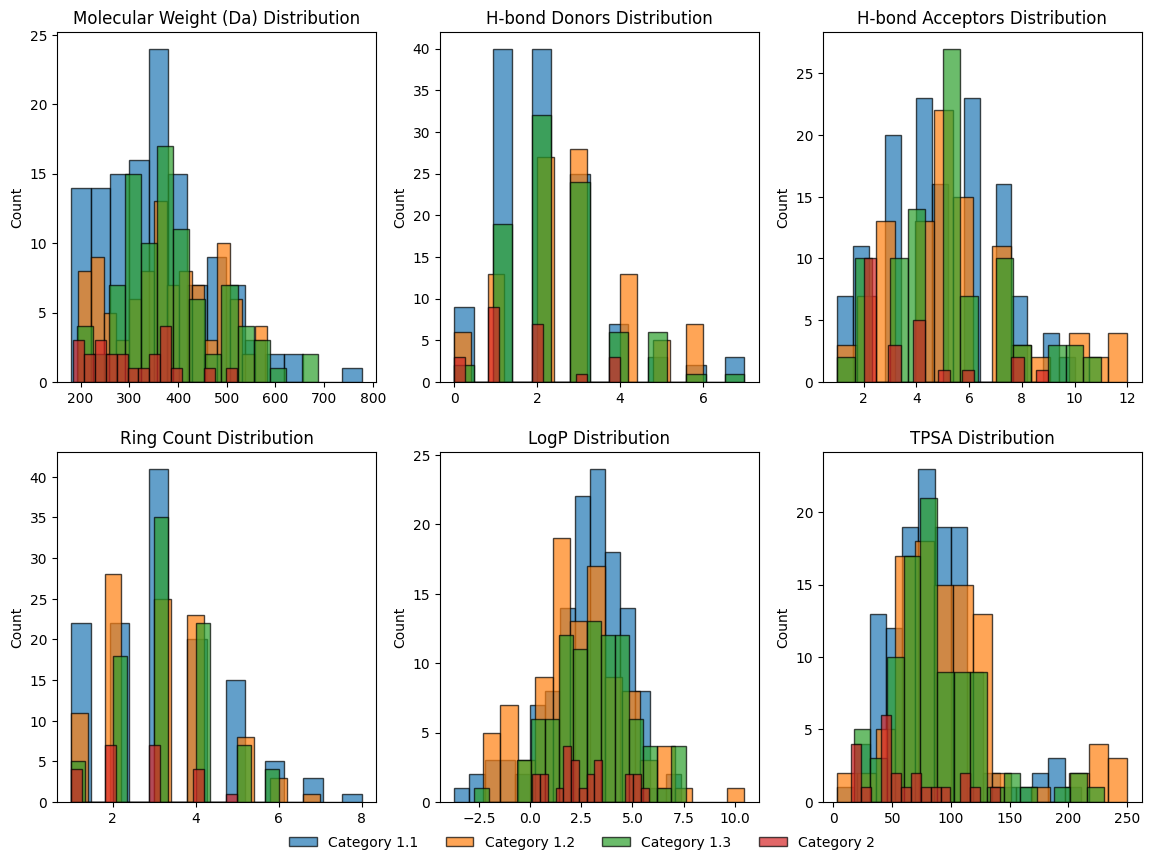

In [12]:
unique_cats = sorted(set(str(category) for _, _, _, category in represenetative_enantiomer_mols))
# Set last color to purple in the palette (late = purple)
palette_colors = sns.color_palette("tab10", n_colors=len(unique_cats))
if len(palette_colors) > 0:
    palette_colors = list(palette_colors)
    palette_colors[-1] = (0.5, 0.0, 0.5)  # Replace last color with purple (RGB normalized)

cat_color_dict = dict(zip(unique_cats, palette_colors))

mol_weights = []
hbd_list = []
hba_list = []
ring_count_list = []
logp_list = []
tpsa_list = []
categories = []

for identifier, mol, group, category in represenetative_enantiomer_mols:
    mol_weights.append(Descriptors.MolWt(mol))
    hbd_list.append(Descriptors.NumHDonors(mol))
    hba_list.append(Descriptors.NumHAcceptors(mol))
    ring_count_list.append(Descriptors.RingCount(mol))
    logp_list.append(Descriptors.MolLogP(mol))
    tpsa_list.append(Descriptors.TPSA(mol))
    categories.append(str(category))

df = pd.DataFrame({
    'MolecularWeight': mol_weights,
    'HBDonors': hbd_list,
    'HBAcceptors': hba_list,
    'RingCount': ring_count_list,
    'LogP': logp_list,
    'TPSA': tpsa_list,
    'Category': categories
})
properties = [
    ('MolecularWeight', 'Molecular Weight (Da)'),
    ('HBDonors', 'H-bond Donors'),
    ('HBAcceptors', 'H-bond Acceptors'),
    ('RingCount', 'Ring Count'),
    ('LogP', 'LogP'),
    ('TPSA', 'TPSA')
]
num_properties = len(properties)
ncols = 3
nrows = (num_properties + ncols - 1) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, nrows * 5))
axes = axes.flatten()

handles_labels_set = False
handles = None
labels = None
for i, (prop, label) in enumerate(properties):
    if i >= len(axes):
        break
    ax = axes[i]
    local_handles = []
    local_labels = []
    for j, cat in enumerate(unique_cats):
        if cat == "invalid":
            continue
        prop_values = df[df['Category'] == cat][prop]
        n, bins, patches = ax.hist(
            prop_values, bins=15, alpha=0.70, 
            label=f'Category {cat}',
            color=cat_color_dict[cat], 
            edgecolor='black'
        )
        if not handles_labels_set and len(patches) > 0:
            local_handles.append(patches[0])
            local_labels.append(f'Category {cat}')
    ax.set_ylabel('Count')
    ax.set_title(f'{label} Distribution')
    # Keep the x ticks label (no action needed here)
    if not handles_labels_set:
        handles = local_handles
        labels = local_labels
        handles_labels_set = True
for j in range(num_properties, len(axes)):
    fig.delaxes(axes[j])
if handles is not None and labels is not None:
    fig.legend(
        handles, labels,
        loc='lower center', bbox_to_anchor=(0.5, 0.05), ncol=len(labels), frameon=False
    )
plt.savefig('physicochemical_property_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
df['Category'].value_counts()

Category
1.1        129
1.2         99
1.3         91
2           23
invalid     20
Name: count, dtype: int64

## Comparison in the figure

In [14]:
feature_table_sorted = feature_table.sort_values(by='maximum_relatedness_rmsd_A', ascending=True)
feature_table_sorted.head(10)

,PSG_identifier,n_structures,n_m0_structures,n_m1_structures,atom_count_unique_values,atom_count_by_file,maximum_relatedness_m0_file,maximum_relatedness_m1_file,maximum_relatedness_rmsd_A,maximum_relatedness_silirid_similarity,maximum_relatedness_m0_silirid,maximum_relatedness_m1_silirid,manual_label,maximum_relatedness_silirid_distance
355,g001947_d9a34d2ed1,4,2,2,17,interaction_7yep_FZ4_A_1001_m0.tsv=17; interac...,interaction_7yep_FZ4_A_1001_m0.tsv,interaction_7yep_FZ4_D_1001_m1.tsv,0.240531,0.833333,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.1,0.166667
66,g000510_5ad9e0ab8f,4,2,2,25,interaction_1x28_PGU_A_413_m0.tsv=25; interact...,interaction_1x28_PGU_A_413_m0.tsv,interaction_1x2a_PDG_A_413_m1.tsv,0.304150,0.976190,"0,0,0,0,0,0,0,0,0,0,8,0,0,4,0,0,0,0,0,0,0,2,0,...","0,0,0,0,0,0,0,0,0,0,8,0,0,4,0,0,0,0,0,0,0,2,0,...",1.1,0.023810
131,g000755_9a85e99288,4,2,2,30,interaction_7um8_NQF_A_302_m1.tsv=30; interact...,interaction_7umw_NUC_B_302_m0.tsv,interaction_7um8_NQF_A_302_m1.tsv,0.305466,1.000000,"0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.1,0.000000
313,g001693_fc5e889c31,52,36,16,19,interaction_4tzc_EF2_A_504_m0.tsv=19; interact...,interaction_5yiz_EF2_t_501_m0.tsv,interaction_5yj1_6EL_G_501_m1.tsv,0.316971,1.000000,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.1,0.000000
316,g001721_dad608c1e5,3,1,2,15,interaction_7h73_Q7X_A_210_m1.tsv=15; interact...,interaction_7h73_Q7X_B_205_m0.tsv,interaction_7h73_Q7X_A_210_m1.tsv,0.340272,1.000000,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.1,0.000000
148,g000863_800ee45188,3,2,1,29,interaction_1exa_394_A_450_m1.tsv=29; interact...,interaction_4lbd_961_A_1_m0.tsv,interaction_1exa_394_A_450_m1.tsv,0.350178,0.923077,"0,0,0,0,0,0,0,0,0,0,3,0,0,1,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,3,0,0,1,0,0,0,0,0,0,0,0,0,...",1.1,0.076923
273,g001351_0773f087d9,8,4,4,38,interaction_2fm0_M98_A_601_m0.tsv=38; interact...,interaction_2fm0_M98_C_603_m0.tsv,interaction_2fm5_M99_C_603_m1.tsv,0.366844,0.904762,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,...",1.1,0.095238
197,g001030_21c6cbac10,6,2,4,27,interaction_5uo5_M4R_A_803_m1.tsv=27; interact...,interaction_5uo7_8FD_A_803_m0.tsv,interaction_5uo6_M4R_A_803_m1.tsv,0.381854,0.785714,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...",1.1,0.214286
84,g000587_09c8a5bf03,5,4,1,26,interaction_1rud_W84_1_290_m0.tsv=26; interact...,interaction_1rui_W84_1_290_m0.tsv,interaction_2rr1_W8R_1_900_m1.tsv,0.392053,0.837838,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.1,0.162162
186,g001014_ec8bff652c,2,1,1,38,interaction_6q7b_HO5_A_1001_m0.tsv=38; interac...,interaction_6q7b_HO5_A_1001_m0.tsv,interaction_6q7e_HMW_A_1001_m1.tsv,0.396353,0.880000,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.1,0.120000


In [15]:
silirid_fingerprint_slot=pd.read_csv('../Data/Notebook_reproduce_data/silirid_fingerprint_slots.csv')
interaction_file_path='/data/local/Pro_2_enantiomers/Organize_script/Data/Pharmacophore/paired_enantiomers_pocket_based'

In [16]:
feature_table.head(5)

,PSG_identifier,n_structures,n_m0_structures,n_m1_structures,atom_count_unique_values,atom_count_by_file,maximum_relatedness_m0_file,maximum_relatedness_m1_file,maximum_relatedness_rmsd_A,maximum_relatedness_silirid_similarity,maximum_relatedness_m0_silirid,maximum_relatedness_m1_silirid,manual_label,maximum_relatedness_silirid_distance
0,g000001_b55a025257,6,4,2,"21,23,25,31,32",interaction_7pql_80S_A_301_m0.tsv=23; interact...,NaN,NaN,NaN,NaN,NaN,NaN,1.1,NaN
1,g000013_cb46fef414,7,5,2,20,interaction_5tiw_OAQ_A_302_m0.tsv=20; interact...,interaction_6b52_OAQ_A_302_m0.tsv,interaction_5tix_OQR_B_302_m1.tsv,3.218487,0.757576,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.3,0.242424
2,g000045_359154acb2,13,12,1,27,interaction_5bk7_EQJ_A_400_m0.tsv=27; interact...,interaction_6c92_EQJ_A_401_m0.tsv,interaction_5dj3_5DK_C_500_m1.tsv,2.537710,0.470588,"0,0,0,0,0,0,0,0,0,0,3,0,0,2,0,0,0,0,0,0,0,3,0,...","0,0,0,0,0,0,0,0,0,0,3,0,0,2,0,0,0,0,0,0,0,2,0,...",1.3,0.529412
3,g000049_6924aac1df,4,1,3,26,interaction_5kcy_XBU_A_501_m1.tsv=26; interact...,interaction_5kd6_LBU_B_501_m0.tsv,interaction_5kcy_XBU_B_501_m1.tsv,4.796130,0.216216,"0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,1,2,0,0,0,0,0,0,0,0,0,...",1.3,0.783784
4,g000066_31f4cbeb1f,4,2,2,31,interaction_6e7u_HX7_B_503_m0.tsv=31; interact...,interaction_6e7u_HX7_D_402_m0.tsv,interaction_6e7v_T88_D_502_m1.tsv,2.038000,1.000000,"0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...","0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...",1.2,0.000000


In [17]:
def find_matched_entries_dic(
    pdb_m0_code,
    feature_table,
    silirid_fingerprint_slot,
    interaction_file_path
):
    row = feature_table[feature_table['atom_count_by_file'].str.contains(pdb_m0_code, na=False)]
    if row.empty:
        raise ValueError(f"No rows found containing pdb_m0_code {pdb_m0_code}")
    maximum_relatedness_m1_file = row['maximum_relatedness_m1_file'].iloc[0]
    pdb_m1_code = '_'.join(maximum_relatedness_m1_file.split('_')[1:4])
    m0_silirid_str = row.iloc[0]['maximum_relatedness_m0_silirid']
    m1_silirid_str = row.iloc[0]['maximum_relatedness_m1_silirid']
    group_identifier = row['PSG_identifier'].iloc[0].split('_')[0]
    m0_list = [int(x) for x in m0_silirid_str.strip().split(',')]
    m1_list = [int(x) for x in m1_silirid_str.strip().split(',')]
    assert len(m0_list) == len(m1_list), "m0 and m1 silirid lists must have the same length"
    nonzero_indices = [i for i, (m0, m1) in enumerate(zip(m0_list, m1_list)) if m0 != 0 or m1 != 0]
    m0_nonzero = [m0_list[i] for i in nonzero_indices]
    m1_nonzero = [m1_list[i] for i in nonzero_indices]
    m0_nonzero_str = ','.join(map(str, m0_nonzero))
    m1_nonzero_str = ','.join(map(str, m1_nonzero))
    matched_entries_dic = {}
    for filename in os.listdir(interaction_file_path):
        if filename.startswith('.~lock.') or filename.startswith('.'):
            continue
        if group_identifier in filename:
            file_path = os.path.join(interaction_file_path, filename)
            interaction_df = pd.read_csv(file_path)
            for nonzero_index in nonzero_indices:
                amino_acid = silirid_fingerprint_slot['amino_acid'].iloc[nonzero_index]
                interaction_type_feature = silirid_fingerprint_slot['feature_type'].iloc[nonzero_index]
                pattern_key = amino_acid+'_'+interaction_type_feature
                mask_pdb = (
                    interaction_df['file'].astype(str).str.contains(pdb_m1_code, na=False) |
                    interaction_df['file'].astype(str).str.contains(pdb_m0_code, na=False)
                )
                mask_feature_type = interaction_df['feature_type'] == interaction_type_feature
                if 'pocket_residues' in interaction_df.columns:
                    pocket_values = interaction_df['pocket_residues'].fillna('').astype(str)
                    mask_pocket = pocket_values.apply(
                        lambda x: any(amino_acid in residue for residue in x.split(', '))
                    )
                else:
                    mask_pocket = pd.Series([False]*len(interaction_df), index=interaction_df.index)
                matches = interaction_df[mask_pdb & mask_feature_type & mask_pocket]
                if not matches.empty:
                    matched_entries_dic[pattern_key] = matches
    return matched_entries_dic, m0_nonzero_str, m1_nonzero_str, pdb_m1_code, nonzero_indices

In [18]:
pdb_m0_code = '3n2k_K2N_B'
matched_entries_dic, m0_nonzero_str, m1_nonzero_str, pdb_m1_code, nonzero_indices = find_matched_entries_dic(
    pdb_m0_code,
    feature_table,
    silirid_fingerprint_slot,
    interaction_file_path
)
print(pdb_m0_code,m0_nonzero_str)
print(pdb_m1_code,m1_nonzero_str)
print(matched_entries_dic.keys())

3n2k_K2N_B 2,8,13,0,0,0,7,0
3n2g_G2N_B 1,12,18,1,1,6,11,1
dict_keys(['GLU_H_BOND_DONOR', 'ILE_HYDROPHOBIC', 'LEU_HYDROPHOBIC', 'LEU_H_BOND_DONOR', 'PHE_HYDROPHOBIC', 'TYR_AROMATIC', 'VAL_HYDROPHOBIC', 'VAL_H_BOND_DONOR'])


In [19]:
matched_entries_dic['VAL_H_BOND_DONOR']

,atom_index,file,feature_type,pocket_residues,functional_group,enantiomer_short_hash
74,39,interaction_3n2g_G2N_B_700_m1.tsv,H_BOND_DONOR,VAL_238_B,N([R])[R],43b2c98b18


In [20]:
counts_contains_same_pdb = feature_table.loc[
    (feature_table['maximum_relatedness_m0_file'].notna()) &
    (feature_table['maximum_relatedness_m1_file'].notna()) &
    (feature_table['maximum_relatedness_m0_file'].str.split('_').str[1] == feature_table['maximum_relatedness_m1_file'].str.split('_').str[1])
]['manual_label'].value_counts()
print(counts_contains_same_pdb)

manual_label
1.1        25
2          21
1.3        17
invalid     9
1.2         7
Name: count, dtype: int64


In [21]:
counts_contains_same_pdb_and_same_chain = feature_table.loc[
    (feature_table['maximum_relatedness_m0_file'].notna()) &
    (feature_table['maximum_relatedness_m1_file'].notna()) &
    (feature_table['maximum_relatedness_m0_file'].str.split('_').str[1] == feature_table['maximum_relatedness_m1_file'].str.split('_').str[1]) &
    (feature_table['maximum_relatedness_m0_file'].str.split('_').str[3] == feature_table['maximum_relatedness_m1_file'].str.split('_').str[3])
]['manual_label'].value_counts()
print(counts_contains_same_pdb_and_same_chain)

manual_label
2          19
1.3         8
1.1         5
invalid     2
Name: count, dtype: int64


In [22]:
def rmsd_to_category(rmsd):
    if pd.isna(rmsd):
        return pd.NA
    if rmsd <= 1.25:
        return "1.1"
    if rmsd <= 2.5:
        return "1.2"
    if rmsd <= 11:
        return "1.3"
    return "2"

label_order = ["1.1", "1.2", "1.3", "2"]
eval_df = feature_table.copy()
eval_df["rmsd_pred_label"] = eval_df["maximum_relatedness_rmsd_A"].map(rmsd_to_category)
eval_df["manual_label"] = (
    eval_df["manual_label"].astype(str).replace({"2.0": "2", "nan": pd.NA, "None": pd.NA})
)

print("Rows in feature_table:", len(eval_df))
print("Rows with RMSD:", int(eval_df["rmsd_pred_label"].notna().sum()))
print("Rows missing RMSD:", int(eval_df["rmsd_pred_label"].isna().sum()))
print()
print("1) Predicted category counts (whole dataframe, RMSD present)")
pred_counts = (
    eval_df["rmsd_pred_label"]
    .value_counts(dropna=True)
    .reindex(label_order)
    .fillna(0)
    .astype(int)
)
print(pred_counts.to_string())
print("Total assigned:", int(pred_counts.sum()))

labeled = eval_df[
    eval_df["rmsd_pred_label"].notna() & eval_df["manual_label"].isin(label_order)
].copy()
agree = labeled["rmsd_pred_label"] == labeled["manual_label"]
print()
print("2) Agreement with manual_label (RMSD present and label in 1.1/1.2/1.3/2)")
print(f"  labeled rows with RMSD: {len(labeled)}")
print(f"  agree: {int(agree.sum())}")
print(f"  disagree: {int((~agree).sum())}")
print()
print("Confusion (rows = manual_label, columns = RMSD-predicted)")
confusion = (
    pd.crosstab(
        labeled["manual_label"],
        labeled["rmsd_pred_label"],
        rownames=["manual"],
        colnames=["predicted"],
    )
    .reindex(index=label_order, columns=label_order)
    .fillna(0)
    .astype(int)
)
display(confusion)
print()
print("Per-class: n_true, n_predicted, n_agree")
per_class = pd.DataFrame({
    "n_true": [(labeled["manual_label"] == cat).sum() for cat in label_order],
    "n_predicted": [(labeled["rmsd_pred_label"] == cat).sum() for cat in label_order],
    "n_agree": [
        ((labeled["manual_label"] == cat) & (labeled["rmsd_pred_label"] == cat)).sum()
        for cat in label_order
    ],
}, index=label_order)
display(per_class)


Rows in feature_table: 362
Rows with RMSD: 349
Rows missing RMSD: 13

1) Predicted category counts (whole dataframe, RMSD present)
rmsd_pred_label
1.1    109
1.2     99
1.3    107
2       34
Total assigned: 349

2) Agreement with manual_label (RMSD present and label in 1.1/1.2/1.3/2)
  labeled rows with RMSD: 328
  agree: 247
  disagree: 81

Confusion (rows = manual_label, columns = RMSD-predicted)


predicted,1.1,1.2,1.3,2
manual,,,,
1.1,91,28,3,2
1.2,13,60,20,0
1.3,0,7,74,7
2,0,0,1,22



Per-class: n_true, n_predicted, n_agree


,n_true,n_predicted,n_agree
1.1,124,104,91
1.2,93,95,60
1.3,88,98,74
2,23,31,22
